# **Quick Start: Train and Evaluate Models**

# Tennis Match Prediction - Ready to Model

## Quick Start

### Step 1: Load your data
```python
import pandas as pd
df = pd.read_csv('features_no_ytd.csv')  # Start with this
# or
df = pd.read_csv('features_with_ytd.csv')  # For more features
```

### Step 2: Run preprocessing
`preprocessing_for_modeling.py`

This will:
- Drop non-predictive columns (names, dates, metadata)
- Handle all NaN values (median for numerical, 'Unknown' for categorical)
- One-hot encode categorical variables
- Create engineered features (rank_diff, elo_diff, etc.)
- Split into train/test (80/20)
- Scale features for linear models
- Output: X_train, X_test, y_train, y_test (and scaled versions)

### Step 3: Train models
`model_training.ipynb`

This will:
- Train Logistic Regression, Random Forest, Gradient Boosting
- Compare to Elo baseline
- Show feature importance
- Print confusion matrix and classification report
- Identify best model

## Files

Data:
- features_no_ytd.csv (49,750 x 40) - Clean, no YTD stats
- features_with_ytd.csv (49,750 x 76) - Includes YTD stats

Scripts:
- preprocessing_for_modeling.py - Data prep
- model_training.py - Train and evaluate models

Documentation:
- FINAL_DATASET_SUMMARY.md - Complete dataset details

## What's in the Data

Target: won (1=player won, 0=player lost)

Key Features:
- player_elo, opponent_elo (Elo ratings)
- player_rank, opponent_rank (ATP ranking)
- player_win_prob_elo (Elo-based probability)
- player_h2h, opponent_h2h (historical head-to-head)
- Surface, Court, Round (match context)
- player_form, opponent_form (recent performance)
- 36 YTD statistics (Version 2 only)

## Expected Performance

Baseline (Elo probability): ~64% accuracy
Your models should: 70-75% accuracy

## Notes

- No data leakage (all post-match stats removed)
- Perfect 50/50 balance (no class imbalance)
- Preprocessing handles all NaN values
- Categorical variables properly encoded
- Features properly scaled for linear models
- Tree models use original scale

Ready to model!

# **Run after "preprocessing_for_modeling.py"

In [31]:
import sys
print(sys.executable)
print(sys.path[:3])

/opt/miniconda3/bin/python
['/opt/miniconda3/lib/python313.zip', '/opt/miniconda3/lib/python3.13', '/opt/miniconda3/lib/python3.13/lib-dynload']


In [32]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
import pandas as pd
import numpy as np
from pathlib import Path

# Assumes you've run preprocessing_for_modeling.py and have:
# X_train, X_test, y_train, y_test (original scale)
# X_train_scaled, X_test_scaled (scaled)

files_to_get = ['X_test.csv', 'y_test.csv', 'X_train.csv', 'y_train.csv','X_test_scaled.csv', 'X_train_scaled.csv', 'X_test_not_encoded.csv', 'X_train_not_encoded.csv']

for i in files_to_get:
    vars()[i.split('.')[0]] = pd.read_csv(Path('../data/processed/model_ready') / i)

print("="*80)
print("MODEL TRAINING AND EVALUATION")
print("="*80)

# Graph x_train, x_test, y_train, y_test shapes
print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")



MODEL TRAINING AND EVALUATION
X_train shape: (39798, 44)
X_test shape: (9952, 44)
y_train shape: (39798, 1)
y_test shape: (9952, 1)


In [33]:
# ============================================================================
# SAVE ALL PREDICTIONS WITH IDENTIFIERS
# ============================================================================

print("="*80)
print("SAVING ALL MODEL PREDICTIONS WITH IDENTIFIERS")
print("="*80)

# Load test identifiers
test_ids = pd.read_csv('../data/processed/model_ready/test_identifiers.csv')

print(f"test_ids: {len(test_ids)} rows")
print(f"y_test: {len(y_test)} rows")

# Verify same length
if len(test_ids) != len(y_test):
    print(f"WARNING: Length mismatch {len(test_ids)} vs {len(y_test)}")
    # Handle mismatch if needed
else:
    print("Lengths match!")

# Create complete predictions dataframe
all_predictions = test_ids.copy()

# Add actual outcome
all_predictions['y_true'] = y_test.values if hasattr(y_test, 'values') else y_test

SAVING ALL MODEL PREDICTIONS WITH IDENTIFIERS
test_ids: 9952 rows
y_test: 9952 rows
Lengths match!


In [34]:
from sklearn.metrics import log_loss, mean_absolute_error, r2_score

def eval_classifier(y_true, y_proba, threshold=0.5):
    """
    y_proba: predicted probability for class 1
    """
    y_pred = (y_proba >= threshold).astype(int)
    
    acc = accuracy_score(y_true, y_pred)
    auc = roc_auc_score(y_true, y_proba)
    ll = log_loss(y_true, y_proba)
    mae = mean_absolute_error(y_true, y_proba)
    r2 = r2_score(y_true, y_proba)  # "variance explained" on 0–1 outcome

    return {
        "accuracy": acc,
        "auc": auc,
        "log_loss": ll,
        "mae": mae,
        "r2": r2
    }
    
dict_results = []
    
# ============================================================================
# BASELINE: Elo Probability
# ============================================================================

print("\n" + "-"*80)
print("BASELINE: ELO PROBABILITY")
print("-"*80)

if 'player_win_prob_elo' in X_test.columns:
    elo_preds = (X_test['player_win_prob_elo'] > 0.5).astype(int)
    elo_probs = X_test['player_win_prob_elo']
    
    print(f"Accuracy: {accuracy_score(y_test, elo_preds):.4f}")
    print(f"ROC AUC: {roc_auc_score(y_test, elo_probs):.4f}")
    print("\nThis is your baseline to beat!")
    
elo_metrics = eval_classifier(y_test, elo_probs)
elo_metrics["model"] = "Baseline Elo"
print(elo_metrics)
if not any(d["model"] == elo_metrics["model"] for d in dict_results):
    dict_results.append(elo_metrics)
    
# Add to all_predictions as prob_Baseline_Elo
all_predictions['prob_Baseline_Elo'] = elo_probs.values
# Add to all_predictions as pred_Baseline_Elo
all_predictions['pred_Baseline_Elo'] = elo_preds.values


--------------------------------------------------------------------------------
BASELINE: ELO PROBABILITY
--------------------------------------------------------------------------------
Accuracy: 0.6302
ROC AUC: 0.6967

This is your baseline to beat!
{'accuracy': 0.6302250803858521, 'auc': 0.6967378303315723, 'log_loss': 0.6268883321705405, 'mae': 0.43189868486195276, 'r2': 0.12208742132757955, 'model': 'Baseline Elo'}


In [35]:
# ============================================================================
# MODEL 1: LOGISTIC REGRESSION (use scaled data)
# ============================================================================

print("\n" + "-"*80)
print("MODEL 1: LOGISTIC REGRESSION")
print("-"*80)

lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
y_prob_lr = lr.predict_proba(X_test_scaled)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob_lr):.4f}")

lr_metrics = eval_classifier(y_test, y_prob_lr)
lr_metrics["model"] = "Logistic Regression"
print(lr_metrics)
if not any(d['model'] == lr_metrics['model'] for d in dict_results):
    dict_results.append(lr_metrics)
    
# Add to all_predictions as prob_Logistic_Regression
all_predictions['prob_Logistic_Regression'] = y_prob_lr
# Add to all_predictions as pred_Logistic_Regression
all_predictions['pred_Logistic_Regression'] = y_pred_lr


--------------------------------------------------------------------------------
MODEL 1: LOGISTIC REGRESSION
--------------------------------------------------------------------------------


/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Accuracy: 0.7216
ROC AUC: 0.8040
{'accuracy': 0.7215635048231511, 'auc': 0.8039758445037788, 'log_loss': 0.5376629330855797, 'mae': 0.3636623434851078, 'r2': 0.27725714694009596, 'model': 'Logistic Regression'}


In [36]:
from statsmodels.stats.outliers_influence import variance_inflation_factor
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

script_dir = Path.cwd()  # Current working directory
out_dir = script_dir / 'figs'  # Or '../figs' if you need to go up
out_dir.mkdir(parents=True, exist_ok=True)

print("="*80)
print("MULTICOLLINEARITY ANALYSIS")
print("="*80)

# ============================================================================
# 1. VARIANCE INFLATION FACTOR (VIF)
# ============================================================================

print("\n" + "-"*80)
print("1. VARIANCE INFLATION FACTOR (VIF)")
print("-"*80)
print("\nVIF measures how much a feature is explained by other features")
print("Rule of thumb: VIF > 10 indicates problematic multicollinearity\n")

# Select only numeric columns for VIF
numeric_cols = X_train_scaled.select_dtypes(include=[np.number]).columns.tolist()
X_numeric = X_train_scaled[numeric_cols].copy()

"""
# Select only numeric columns for VIF without multicollinearity
numeric_cols = X_train_scaled_no_mc.select_dtypes(include=[np.number]).columns.tolist()
X_numeric = X_train_scaled_no_mc[numeric_cols].copy()
"""

# Remove any columns with inf or nan
X_numeric = X_numeric.replace([np.inf, -np.inf], np.nan)
X_numeric = X_numeric.dropna(axis=1)

print(f"Calculating VIF for {len(X_numeric.columns)} numeric features...")
print("(This may take a minute for large datasets)\n")

# Calculate VIF for each feature
vif_data = pd.DataFrame()
vif_data["Feature"] = X_numeric.columns

vif_values = []
for i in range(len(X_numeric.columns)):
    try:
        vif = variance_inflation_factor(X_numeric.values, i)
        vif_values.append(vif)
    except Exception as e:
        print(f"  Warning: Could not calculate VIF for {X_numeric.columns[i]}: {e}")
        vif_values.append(np.nan)

vif_data["VIF"] = vif_values

# Remove any failed calculations
vif_data = vif_data.dropna()

# Sort by VIF
vif_data = vif_data.sort_values('VIF', ascending=False)

print("Top 20 features by VIF:")
print(vif_data.head(20).to_string(index=False))

# Flag problematic features
high_vif = vif_data[vif_data['VIF'] > 10]
print(f"\n\nFeatures with VIF > 10 (problematic): {len(high_vif)}")
if len(high_vif) > 0:
    print(high_vif.to_string(index=False))
    print("\nRECOMMENDATION: Consider removing these features or using regularization")
else:
    print("No features with VIF > 10. Multicollinearity is acceptable.")

# ============================================================================
# 2. CORRELATION MATRIX
# ============================================================================

print("\n" + "-"*80)
print("2. CORRELATION MATRIX")
print("-"*80)

# Use the same numeric columns
# Limit to first 50 features for readability
features_to_check = X_numeric.columns[:50]
corr_matrix = X_numeric[features_to_check].corr()

# Find highly correlated pairs
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i+1, len(corr_matrix.columns)):
        if abs(corr_matrix.iloc[i, j]) > 0.8:
            high_corr_pairs.append({
                'Feature 1': corr_matrix.columns[i],
                'Feature 2': corr_matrix.columns[j],
                'Correlation': corr_matrix.iloc[i, j]
            })

if len(high_corr_pairs) > 0:
    high_corr_df = pd.DataFrame(high_corr_pairs).sort_values('Correlation', 
                                                              key=abs, ascending=False)
    print(f"\nHighly correlated pairs (|r| > 0.8): {len(high_corr_pairs)}")
    print(high_corr_df.head(20).to_string(index=False))
else:
    print("\nNo feature pairs with |correlation| > 0.8")

# ============================================================================
# 3. CONDITION NUMBER
# ============================================================================

print("\n" + "-"*80)
print("3. CONDITION NUMBER")
print("-"*80)

# Calculate condition number on numeric data
U, s, Vt = np.linalg.svd(X_numeric.values, full_matrices=False)
condition_number = s.max() / s.min()

print(f"\nCondition Number: {condition_number:.2f}")
print("\nInterpretation:")
print("  < 30: No multicollinearity concerns")
print("  30-100: Moderate multicollinearity")
print("  > 100: Severe multicollinearity")

if condition_number < 30:
    print(f"\nSTATUS: Good - condition number is {condition_number:.2f}")
elif condition_number < 100:
    print(f"\nWARNING: Moderate multicollinearity (condition number = {condition_number:.2f})")
else:
    print(f"\nWARNING: Severe multicollinearity (condition number = {condition_number:.2f})")

# ============================================================================
# 4. VISUALIZATION: CORRELATION HEATMAP
# ============================================================================

print("\n" + "-"*80)
print("4. CREATING CORRELATION HEATMAP")
print("-"*80)

# Select top features by VIF or importance
top_features = vif_data.head(20)['Feature'].tolist()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(X_numeric[top_features].corr(), 
            annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8},
            ax=ax, annot_kws={'size': 7})
ax.set_title('Correlation Matrix (Top 20 Features by VIF)', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig(out_dir / 'correlation_heatmap.png', dpi=300, bbox_inches='tight')
print(f"Saved: {out_dir / 'correlation_heatmap.png'}")
plt.close()

# ============================================================================
# 5. VIF BAR PLOT
# ============================================================================

fig, ax = plt.subplots(figsize=(12, 8))
top_vif = vif_data.head(25)
colors = ['#e74c3c' if x > 10 else '#3498db' for x in top_vif['VIF']]
ax.barh(range(len(top_vif)), top_vif['VIF'], color=colors)
ax.set_yticks(range(len(top_vif)))
ax.set_yticklabels(top_vif['Feature'])
ax.set_xlabel('VIF Score', fontweight='bold')
ax.set_title('Variance Inflation Factor (VIF) - Top 25 Features', fontweight='bold', fontsize=14)
ax.axvline(x=10, color='red', linestyle='--', linewidth=2, label='VIF = 10 threshold')
ax.legend()
ax.invert_yaxis()
plt.tight_layout()

plt.savefig(out_dir / 'vif_scores.png', dpi=300, bbox_inches='tight')
print(f"Saved: {out_dir / 'vif_scores.png'}")
plt.close()

# ============================================================================
# SUMMARY & RECOMMENDATIONS
# ============================================================================

print("\n" + "="*80)
print("SUMMARY & RECOMMENDATIONS")
print("="*80)

print(f"\nTotal features analyzed: {len(X_numeric.columns)}")
print(f"Features with VIF > 10: {len(high_vif)}")
print(f"Highly correlated pairs (|r| > 0.8): {len(high_corr_pairs)}")
print(f"Condition number: {condition_number:.2f}")

print("\n" + "-"*80)
print("WHAT TO DO ABOUT MULTICOLLINEARITY")
print("-"*80)

if len(high_vif) > 0 or condition_number > 100:
    print("\nYou have multicollinearity issues. Here are solutions:\n")
    
    print("OPTION 1: Remove highly correlated features")
    print("  - Drop features with VIF > 10")
    print("  - Keep the more interpretable one from correlated pairs")
    print("  Example:")
    print("    features_to_drop = vif_data[vif_data['VIF'] > 10]['Feature'].tolist()")
    print("    X_train_reduced = X_train_scaled.drop(columns=features_to_drop)")
    
    print("\nOPTION 2: Use regularization (RECOMMENDED)")
    print("  - L1 (Lasso): Automatically selects features")
    print("  - L2 (Ridge): Shrinks correlated coefficients")
    print("  Example:")
    print("    from sklearn.linear_model import LogisticRegression")
    print("    lr_ridge = LogisticRegression(penalty='l2', C=1.0, max_iter=1000)")
    print("    lr_lasso = LogisticRegression(penalty='l1', solver='saga', C=1.0, max_iter=1000)")
    
    print("\nOPTION 3: PCA (Principal Component Analysis)")
    print("  - Reduces to uncorrelated components")
    print("  - Loses interpretability")
    print("  Example:")
    print("    from sklearn.decomposition import PCA")
    print("    pca = PCA(n_components=50)")
    print("    X_train_pca = pca.fit_transform(X_train_scaled)")
    
    print("\nOPTION 4: Use tree-based models instead")
    print("  - Random Forest, XGBoost don't care about multicollinearity")
    print("  - Usually perform better for this type of data anyway")
else:
    print("\nGood news! Multicollinearity is not a major issue.")
    print("Your logistic regression should work fine.")
    print("\nStill consider L2 regularization to improve generalization:")
    print("  LogisticRegression(penalty='l2', C=1.0)")

print("\n" + "="*80)
print("ANALYSIS COMPLETE")
print("="*80)
print("\nGenerated files:")
print(f"  - {out_dir / 'correlation_heatmap.png'}")
print(f"  - {out_dir / 'vif_scores.png'}")

MULTICOLLINEARITY ANALYSIS

--------------------------------------------------------------------------------
1. VARIANCE INFLATION FACTOR (VIF)
--------------------------------------------------------------------------------

VIF measures how much a feature is explained by other features
Rule of thumb: VIF > 10 indicates problematic multicollinearity

Calculating VIF for 28 numeric features...
(This may take a minute for large datasets)



/opt/miniconda3/lib/python3.13/site-packages/statsmodels/stats/outliers_influence.py:197: RuntimeWarning: divide by zero encountered in scalar divide
  vif = 1. / (1. - r_squared_i)


Top 20 features by VIF:
        Feature          VIF
opponent_rating          inf
      rank_diff          inf
    rating_diff          inf
    height_diff          inf
    player_rank          inf
  player_rating          inf
   opponent_age          inf
opponent_height          inf
     player_age          inf
  player_height          inf
    points_diff          inf
   opponent_elo          inf
opponent_points          inf
  opponent_rank          inf
       age_diff          inf
     player_elo          inf
  player_points          inf
       elo_diff          inf
  proba_form_50 9.281866e+08
  opponent_form 7.459972e+08


Features with VIF > 10 (problematic): 22
            Feature          VIF
    opponent_rating          inf
          rank_diff          inf
        rating_diff          inf
        height_diff          inf
        player_rank          inf
      player_rating          inf
       opponent_age          inf
    opponent_height          inf
         player_age        

/opt/miniconda3/lib/python3.13/site-packages/matplotlib/transforms.py:2437: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
/opt/miniconda3/lib/python3.13/site-packages/matplotlib/transforms.py:2437: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


Saved: /Users/ecemyildirim/Documents/GitHub/tennis_betting_efficiency/notebooks/figs/vif_scores.png

SUMMARY & RECOMMENDATIONS

Total features analyzed: 28
Features with VIF > 10: 22
Highly correlated pairs (|r| > 0.8): 5
Condition number: 6491230936764752.00

--------------------------------------------------------------------------------
WHAT TO DO ABOUT MULTICOLLINEARITY
--------------------------------------------------------------------------------

You have multicollinearity issues. Here are solutions:

OPTION 1: Remove highly correlated features
  - Drop features with VIF > 10
  - Keep the more interpretable one from correlated pairs
  Example:
    features_to_drop = vif_data[vif_data['VIF'] > 10]['Feature'].tolist()
    X_train_reduced = X_train_scaled.drop(columns=features_to_drop)

OPTION 2: Use regularization (RECOMMENDED)
  - L1 (Lasso): Automatically selects features
  - L2 (Ridge): Shrinks correlated coefficients
  Example:
    from sklearn.linear_model import LogisticReg

In [37]:
"""
Fix Multicollinearity - Remove Redundant Features
Run this AFTER preprocessing_for_modeling.py

Two strategies provided:
1. Keep DIFFERENCES, drop original pairs (RECOMMENDED)
2. Keep ORIGINALS, drop differences
"""

import pandas as pd
import numpy as np

print("="*80)
print("FIXING MULTICOLLINEARITY")
print("="*80)

print("\nPROBLEM: Perfect multicollinearity detected")
print("  - age_diff = player_age - opponent_age")
print("  - rank_diff = player_rank - opponent_rank")
print("  - elo_diff = player_elo - opponent_elo")
print("\nSOLUTION: Drop redundant features")

# ============================================================================
# STRATEGY 1: KEEP DIFFERENCES (RECOMMENDED)
# ============================================================================

print("\n" + "-"*80)
print("STRATEGY 1: KEEP DIFFERENCES, DROP ORIGINALS (RECOMMENDED)")
print("-"*80)

# Drop the original features, keep the differences
features_to_drop_v1 = [
    'player_age', 'opponent_age',      # Keep age_diff
    'player_rank', 'opponent_rank',    # Keep rank_diff
    'player_elo', 'opponent_elo',      # Keep elo_diff
    'player_form', 'opponent_form',  # 'player_form' feature also causes multicollinearity
    'player_height', 'opponent_height',
    'player_points', 'opponent_points',
    'player_rating', 'opponent_rating',
    'player_form', 'opponent_form',
    'rank_diff', 'elo_diff', 'form_diff',  # Drop raw differences
]

# Only drop if they exist
features_to_drop_v1 = [f for f in features_to_drop_v1 if f in X_train.columns]

X_train_fixed_v1 = X_train.drop(columns=features_to_drop_v1)
X_test_fixed_v1 = X_test.drop(columns=features_to_drop_v1)

X_train_scaled_fixed_v1 = X_train_scaled.drop(columns=features_to_drop_v1)
X_test_scaled_fixed_v1 = X_test_scaled.drop(columns=features_to_drop_v1)

print(f"\nDropped {len(features_to_drop_v1)} features: {features_to_drop_v1}")
print(f"New shape: {X_train_fixed_v1.shape}")


"""
# ============================================================================
# STRATEGY 2: KEEP ORIGINALS (ALTERNATIVE)
# ============================================================================

print("\n" + "-"*80)
print("STRATEGY 2: KEEP ORIGINALS, DROP DIFFERENCES (ALTERNATIVE)")
print("-"*80)

# Drop the engineered differences, keep original features
features_to_drop_v2 = [
    'age_diff',      # Keep player_age, opponent_age
    'rank_diff',     # Keep player_rank, opponent_rank
    'elo_diff'       # Keep player_elo, opponent_elo
]

features_to_drop_v2 = [f for f in features_to_drop_v2 if f in X_train.columns]

X_train_fixed_v2 = X_train.drop(columns=features_to_drop_v2)
X_test_fixed_v2 = X_test.drop(columns=features_to_drop_v2)

X_train_scaled_fixed_v2 = X_train_scaled.drop(columns=features_to_drop_v2)
X_test_scaled_fixed_v2 = X_test_scaled.drop(columns=features_to_drop_v2)

print(f"\nDropped {len(features_to_drop_v2)} features: {features_to_drop_v2}")
print(f"New shape: {X_train_fixed_v2.shape}")

# ============================================================================
# COMPARISON
# ============================================================================

print("\n" + "="*80)
print("WHICH STRATEGY TO USE?")
print("="*80)

print("\nSTRATEGY 1 (Keep Differences) - RECOMMENDED")
print("  Pros:")
print("    - More interpretable (difference directly shows advantage)")
print("    - Fewer features (simpler model)")
print("    - Captures relative strength directly")
print("  Cons:")
print("    - Loses absolute values (might matter for some contexts)")
print("  Use for: Most prediction tasks")

print("\nSTRATEGY 2 (Keep Originals)")
print("  Pros:")
print("    - Keeps absolute values")
print("    - Model learns the difference automatically")
print("  Cons:")
print("    - More features (more complex)")
print("    - Perfect multicollinearity between pairs")
print("  Use for: When absolute values matter")
"""

# ============================================================================
# RECOMMENDED: USE STRATEGY 1
# ============================================================================

print("\n" + "="*80)
print("USING STRATEGY 1 (RECOMMENDED)")
print("="*80)

# Set the recommended versions as the main variables
X_train_no_mc = X_train_fixed_v1
X_test_no_mc = X_test_fixed_v1
X_train_scaled_no_mc = X_train_scaled_fixed_v1
X_test_scaled_no_mc = X_test_scaled_fixed_v1

print(f"\nCreated new variables without multicollinearity:")
print(f"  X_train_no_mc: {X_train_no_mc.shape}")
print(f"  X_test_no_mc: {X_test_no_mc.shape}")
print(f"  X_train_scaled_no_mc: {X_train_scaled_no_mc.shape}")
print(f"  X_test_scaled_no_mc: {X_test_scaled_no_mc.shape}")

print("\n" + "="*80)
print("NOW RETRAIN YOUR MODEL")
print("="*80)

print("\nUse these variables instead of the original ones:")

from sklearn.linear_model import LogisticRegression

# Retrain without multicollinearity
lr_fixed = LogisticRegression(max_iter=1000, random_state=42)
lr_fixed.fit(X_train_scaled_no_mc, y_train)

y_pred_fixed = lr_fixed.predict(X_test_scaled_no_mc)
y_prob_fixed = lr_fixed.predict_proba(X_test_scaled_no_mc)[:, 1]

from sklearn.metrics import accuracy_score, roc_auc_score
print(f"Accuracy: {accuracy_score(y_test, y_pred_fixed):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob_fixed):.4f}")

lr_no_mc_metrics = eval_classifier(y_test, y_prob_fixed)
lr_no_mc_metrics["model"] = "Logistic Regression (No Multicollinearity)"
print(lr_no_mc_metrics)
if not any(d["model"] == lr_no_mc_metrics["model"] for d in dict_results):
    dict_results.append(lr_no_mc_metrics)
    
# Add to all_predictions as prob_Logistic_Regression_No_MC
all_predictions['prob_Logistic_Regression_No_MC'] = y_prob_fixed
# Add to all_predictions as pred_Logistic_Regression_No_MC
all_predictions['pred_Logistic_Regression_No_MC'] = y_pred_fixed

"""
print("\nOR use regularization with the original data:")

# Ridge (L2 regularization) - handles multicollinearity
lr_ridge = LogisticRegression(penalty='l2', C=1.0, max_iter=1000, random_state=42)
lr_ridge.fit(X_train_scaled, y_train)

# Lasso (L1 regularization) - does feature selection
lr_lasso = LogisticRegression(penalty='l1', solver='saga', C=1.0, max_iter=1000, random_state=42)
lr_lasso.fit(X_train_scaled, y_train)

"""

print("\n" + "="*80)
print("DONE")
print("="*80)


FIXING MULTICOLLINEARITY

PROBLEM: Perfect multicollinearity detected
  - age_diff = player_age - opponent_age
  - rank_diff = player_rank - opponent_rank
  - elo_diff = player_elo - opponent_elo

SOLUTION: Drop redundant features

--------------------------------------------------------------------------------
STRATEGY 1: KEEP DIFFERENCES, DROP ORIGINALS (RECOMMENDED)
--------------------------------------------------------------------------------

Dropped 19 features: ['player_age', 'opponent_age', 'player_rank', 'opponent_rank', 'player_elo', 'opponent_elo', 'player_form', 'opponent_form', 'player_height', 'opponent_height', 'player_points', 'opponent_points', 'player_rating', 'opponent_rating', 'player_form', 'opponent_form', 'rank_diff', 'elo_diff', 'form_diff']
New shape: (39798, 27)

USING STRATEGY 1 (RECOMMENDED)

Created new variables without multicollinearity:
  X_train_no_mc: (39798, 27)
  X_test_no_mc: (9952, 27)
  X_train_scaled_no_mc: (39798, 27)
  X_test_scaled_no_mc: (9

/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Accuracy: 0.7195
ROC AUC: 0.8026
{'accuracy': 0.7194533762057878, 'auc': 0.8025662650174212, 'log_loss': 0.5390412436540409, 'mae': 0.36439341582983026, 'r2': 0.2747236439321822, 'model': 'Logistic Regression (No Multicollinearity)'}

DONE


In [38]:
"""
Visualize Logistic Regression Results
Shows predicted probabilities, ROC curve, and decision boundary
"""

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve, auc, confusion_matrix
from sklearn.decomposition import PCA

sns.set_style("whitegrid")

# Assumes you have: lr_fixed, y_test, y_pred_fixed, y_prob_fixed

# ============================================================================
# CREATE COMPREHENSIVE FIGURE
# ============================================================================

fig = plt.figure(figsize=(16, 10))
fig.suptitle('Logistic Regression: Model Performance', fontsize=16, fontweight='bold')

# ============================================================================
# 1. PREDICTED PROBABILITIES BY ACTUAL OUTCOME
# ============================================================================

ax1 = plt.subplot(2, 3, 1)

# Convert y_test to array if needed
if hasattr(y_test, 'values'):
    y_test_array = y_test.values.ravel()
else:
    y_test_array = np.array(y_test).ravel()

# Probabilities for actual winners and losers
winners_probs = y_prob_fixed[y_test_array == 1]
losers_probs = y_prob_fixed[y_test_array == 0]

ax1.hist(losers_probs, bins=50, alpha=0.7, label='Actual Losers', 
         color='#e74c3c', density=True)
ax1.hist(winners_probs, bins=50, alpha=0.7, label='Actual Winners', 
         color='#2ecc71', density=True)
ax1.axvline(x=0.5, color='black', linestyle='--', linewidth=2, label='Decision threshold')
ax1.set_xlabel('Predicted Probability of Winning')
ax1.set_ylabel('Density')
ax1.set_title('Predicted Probabilities by Actual Outcome')
ax1.legend()
ax1.grid(True, alpha=0.3)

# ============================================================================
# 2. ROC CURVE
# ============================================================================

ax2 = plt.subplot(2, 3, 2)

fpr, tpr, thresholds = roc_curve(y_test_array, y_prob_fixed)
roc_auc = auc(fpr, tpr)

ax2.plot(fpr, tpr, color='#3498db', linewidth=2, 
         label=f'ROC Curve (AUC = {roc_auc:.4f})')
ax2.plot([0, 1], [0, 1], color='gray', linestyle='--', linewidth=1, label='Random (AUC = 0.5)')
ax2.fill_between(fpr, tpr, alpha=0.2, color='#3498db')
ax2.set_xlabel('False Positive Rate')
ax2.set_ylabel('True Positive Rate')
ax2.set_title('ROC Curve')
ax2.legend(loc='lower right')
ax2.grid(True, alpha=0.3)

# ============================================================================
# 3. CONFUSION MATRIX
# ============================================================================

ax3 = plt.subplot(2, 3, 3)

cm = confusion_matrix(y_test_array, y_pred_fixed)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', square=True, 
            cbar_kws={'label': 'Count'}, ax=ax3)
ax3.set_xlabel('Predicted')
ax3.set_ylabel('Actual')
ax3.set_xticklabels(['Loss (0)', 'Win (1)'])
ax3.set_yticklabels(['Loss (0)', 'Win (1)'])
ax3.set_title('Confusion Matrix')

# Add accuracy
accuracy = (cm[0,0] + cm[1,1]) / cm.sum()
ax3.text(0.5, -0.15, f'Accuracy: {accuracy:.4f}', 
         ha='center', transform=ax3.transAxes, fontsize=11, fontweight='bold')

# ============================================================================
# 4. CALIBRATION PLOT
# ============================================================================

ax4 = plt.subplot(2, 3, 4)

# Bin predictions and calculate actual win rate
n_bins = 10
bins = np.linspace(0, 1, n_bins + 1)
bin_centers = (bins[:-1] + bins[1:]) / 2

actual_rates = []
predicted_rates = []

for i in range(n_bins):
    mask = (y_prob_fixed >= bins[i]) & (y_prob_fixed < bins[i+1])
    if mask.sum() > 0:
        actual_rates.append(y_test_array[mask].mean())
        predicted_rates.append(y_prob_fixed[mask].mean())
    else:
        actual_rates.append(np.nan)
        predicted_rates.append(bin_centers[i])

ax4.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Perfect calibration')
ax4.plot(predicted_rates, actual_rates, 'o-', color='#3498db', linewidth=2, 
         markersize=8, label='Model')
ax4.set_xlabel('Predicted Probability')
ax4.set_ylabel('Actual Win Rate')
ax4.set_title('Calibration Plot')
ax4.legend()
ax4.grid(True, alpha=0.3)
ax4.set_xlim([0, 1])
ax4.set_ylim([0, 1])

# ============================================================================
# 5. PREDICTION DISTRIBUTION
# ============================================================================

ax5 = plt.subplot(2, 3, 5)

ax5.scatter(range(len(y_prob_fixed[:1000])), y_prob_fixed[:1000], 
           c=y_test_array[:1000], cmap='RdYlGn', alpha=0.5, s=20)
ax5.axhline(y=0.5, color='black', linestyle='--', linewidth=1)
ax5.set_xlabel('Sample Index (first 1000)')
ax5.set_ylabel('Predicted Probability')
ax5.set_title('Predicted Probabilities (colored by actual outcome)')
ax5.set_ylim([0, 1])
ax5.grid(True, alpha=0.3)

# ============================================================================
# 6. TOP COEFFICIENTS
# ============================================================================

ax6 = plt.subplot(2, 3, 6)

# Get feature names and coefficients
if hasattr(X_train_scaled_no_mc, 'columns'):
    feature_names = X_train_scaled_no_mc.columns
else:
    feature_names = [f'Feature_{i}' for i in range(lr_fixed.coef_.shape[1])]

coef_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': lr_fixed.coef_[0]
})
coef_df['Abs_Coef'] = abs(coef_df['Coefficient'])
coef_df = coef_df.sort_values('Abs_Coef', ascending=False).head(15)

colors = ['#2ecc71' if x > 0 else '#e74c3c' for x in coef_df['Coefficient']]
ax6.barh(range(len(coef_df)), coef_df['Coefficient'], color=colors)
ax6.set_yticks(range(len(coef_df)))
ax6.set_yticklabels(coef_df['Feature'], fontsize=8)
ax6.set_xlabel('Coefficient Value')
ax6.set_title('Top 15 Features by Coefficient Magnitude')
ax6.axvline(x=0, color='black', linestyle='-', linewidth=0.5)
ax6.invert_yaxis()
ax6.grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig(out_dir / 'logistic_regression_results.png', dpi=300, bbox_inches='tight')
print(f"Saved: {out_dir / 'logistic_regression_results.png'}")
plt.close()

# ============================================================================
# SIMPLE 2D DECISION BOUNDARY (BONUS)
# ============================================================================

print("\n" + "-"*80)
print("Creating 2D decision boundary visualization...")
print("-"*80)

# Find best 2 features to use (preferably elo_diff and rank_diff)
possible_pairs = [
    ('elo_diff', 'rank_diff'),
    ('player_win_prob_elo', 'rank_diff'),
    ('player_win_prob_elo', 'form_diff'),
    ('elo_diff', 'form_diff')
]

feature_pair = None
for feat1, feat2 in possible_pairs:
    if feat1 in X_train_scaled_no_mc.columns and feat2 in X_train_scaled_no_mc.columns:
        feature_pair = (feat1, feat2)
        break

# If none of the preferred pairs exist, just use first 2 numerical columns
if feature_pair is None:
    numeric_cols = X_train_scaled_no_mc.select_dtypes(include=[np.number]).columns[:2]
    if len(numeric_cols) >= 2:
        feature_pair = (numeric_cols[0], numeric_cols[1])

if feature_pair is not None:
    feat1, feat2 = feature_pair
    print(f"Using features: {feat1} and {feat2}")
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    # Get the two features
    x1 = X_test_scaled_no_mc[feat1].values
    x2 = X_test_scaled_no_mc[feat2].values
    
    # Scatter actual test points
    scatter = ax.scatter(x1, x2, c=y_test_array, cmap='RdYlGn', 
                        alpha=0.4, s=30, edgecolors='black', linewidth=0.5)
    
    # Create mesh for decision boundary
    x1_min, x1_max = x1.min() - 0.5, x1.max() + 0.5
    x2_min, x2_max = x2.min() - 0.5, x2.max() + 0.5
    xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                           np.linspace(x2_min, x2_max, 200))
    
    # Get coefficients for these two features
    feat1_idx = list(X_train_scaled_no_mc.columns).index(feat1)
    feat2_idx = list(X_train_scaled_no_mc.columns).index(feat2)
    
    # Calculate decision boundary (simplified - using only these 2 features)
    intercept = lr_fixed.intercept_[0]
    coef_feat1 = lr_fixed.coef_[0][feat1_idx]
    coef_feat2 = lr_fixed.coef_[0][feat2_idx]
    
    # Decision boundary: coef1*x1 + coef2*x2 + intercept = 0
    # Solve for x2: x2 = -(intercept + coef1*x1) / coef2
    if abs(coef_feat2) > 0.001:  # Avoid division by zero
        x1_line = np.linspace(x1_min, x1_max, 100)
        x2_line = -(intercept + coef_feat1 * x1_line) / coef_feat2
        
        # Only plot line if it's within reasonable bounds
        if x2_line.min() < x2_max * 2 and x2_line.max() > x2_min * 2:
            ax.plot(x1_line, x2_line, 'k-', linewidth=3, label='Decision Boundary (simplified)')
    
    ax.set_xlabel(f'{feat1} (scaled)', fontsize=12)
    ax.set_ylabel(f'{feat2} (scaled)', fontsize=12)
    ax.set_title(f'Logistic Regression Decision Boundary\n(Using {feat1} and {feat2})', 
                fontsize=14, fontweight='bold')
    ax.axhline(y=0, color='gray', linestyle='--', alpha=0.5)
    ax.axvline(x=0, color='gray', linestyle='--', alpha=0.5)
    
    plt.colorbar(scatter, ax=ax, label='Actual Outcome')
    ax.legend(loc='upper left')
    ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.savefig(out_dir / 'logistic_regression_decision_boundary.png', dpi=300, bbox_inches='tight')
    print(f"Saved: {out_dir / 'logistic_regression_decision_boundary.png'}")
    plt.close()
else:
    print("Could not create decision boundary - no suitable feature pairs found")

print("\n" + "="*80)
print("VISUALIZATION COMPLETE")
print("="*80)
print("\nGenerated visualizations:")
print("  1. logistic_regression_results.png - 6-panel overview")
print("  2. logistic_regression_decision_boundary.png - 2D decision boundary")
print("\nKey insights:")
print("  - Predicted probabilities separate winners/losers")
print("  - ROC curve shows model discrimination ability")
print("  - Calibration plot shows if probabilities are accurate")
print("  - Coefficients show which features matter most")

Saved: /Users/ecemyildirim/Documents/GitHub/tennis_betting_efficiency/notebooks/figs/logistic_regression_results.png

--------------------------------------------------------------------------------
Creating 2D decision boundary visualization...
--------------------------------------------------------------------------------
Using features: Best of and player_h2h
Saved: /Users/ecemyildirim/Documents/GitHub/tennis_betting_efficiency/notebooks/figs/logistic_regression_decision_boundary.png

VISUALIZATION COMPLETE

Generated visualizations:
  1. logistic_regression_results.png - 6-panel overview
  2. logistic_regression_decision_boundary.png - 2D decision boundary

Key insights:
  - Predicted probabilities separate winners/losers
  - ROC curve shows model discrimination ability
  - Calibration plot shows if probabilities are accurate
  - Coefficients show which features matter most


# Logistic Regression Decision Boundary Interpretation

## Overview

**The black line** is your logistic regression's decision boundary - where predicted probability = 50%. It's the "fitted line" equivalent.


## What the Plot Tells You

### 1. Decision Rule

- **Above the line** → Model predicts WIN (green region)
- **Below the line** → Model predicts LOSS (red region)
- **On the line** → 50/50 prediction

### 2. How It Makes Decisions

The line slopes upward, meaning BOTH features matter:

- **Right side (higher player_win_prob_elo)** → More likely to win
- **Below zero on y-axis (negative rank_diff)** → Player has BETTER rank (lower number = better)
  - Remember: `rank_diff = player_rank - opponent_rank`
  - Negative = player has lower (better) ranking

### 3. Model Performance

- **Green points above line** = Correct predictions (true positives)
- **Red points below line** = Correct predictions (true negatives)
- **Red points above line** = Errors (false positives)
- **Green points below line** = Errors (false negatives)

### 4. Pattern Quality

You can see:

- Clear separation trend (green mostly right/above, red mostly left/below)
- BUT substantial overlap in the middle (realistic for sports)
- The model can't perfectly separate them (no model can in real tennis!)


## What This Means Practically

**Example interpretations along the line:**

- High Elo probability but bad rank → Still might win
- Low Elo probability but good rank → Might pull upset
- Both favorable → Almost certainly win (top-right, all green)
- Both unfavorable → Almost certainly lose (bottom-left, all red)

**The model learned:** "Player wins when they have higher Elo probability AND better ranking, weighted by these coefficients."

This is a good result - shows your model is using both features intelligently!

In [39]:
# ============================================================================
# MODEL 2: RANDOM FOREST (use original scale)
# ============================================================================

print("\n" + "-"*80)
print("MODEL 2: RANDOM FOREST")
print("-"*80)

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob_rf):.4f}")

rf_metrics = eval_classifier(y_test, y_prob_rf)
rf_metrics["model"] = "Random Forest"
print(rf_metrics)
if 'Random Forest' not in [d['model'] for d in dict_results]:
    dict_results.append(rf_metrics)
    
# Add to all_predictions as prob_Random_Forest
all_predictions['prob_Random_Forest'] = y_prob_rf
# Add to all_predictions as pred_Random_Forest
all_predictions['pred_Random_Forest'] = y_pred_rf

# Feature importance
feature_importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 10 Important Features:")
print(feature_importance.head(10).to_string(index=False))

# Also do feature importance for data without multicollinearity

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_no_mc, y_train)

y_pred_rf_no_mc = rf.predict(X_test_no_mc)
y_prob_rf_no_mc = rf.predict_proba(X_test_no_mc)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_rf_no_mc):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob_rf_no_mc):.4f}")

rf_metrics = eval_classifier(y_test, y_prob_rf_no_mc)
rf_metrics["model"] = "Random Forest (No Multicollinearity)"
print(rf_metrics)
if 'Random Forest (No Multicollinearity)' not in [d['model'] for d in dict_results]:
    dict_results.append(rf_metrics)

feature_importance_no_mc = pd.DataFrame({
    'feature': X_train_no_mc.columns,
    'importance': rf.fit(X_train_no_mc, y_train).feature_importances_
}).sort_values('importance', ascending=False)


print("\nTop 10 Important Features without multicollinearity:")
print(feature_importance_no_mc.head(10).to_string(index=False))


--------------------------------------------------------------------------------
MODEL 2: RANDOM FOREST
--------------------------------------------------------------------------------


/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Accuracy: 0.7197
ROC AUC: 0.8002
{'accuracy': 0.7201567524115756, 'auc': 0.8002370179110534, 'log_loss': 0.5416708607794629, 'mae': 0.37060088424437304, 'r2': 0.27010321543408355, 'model': 'Random Forest'}

Top 10 Important Features:
            feature  importance
player_win_prob_elo    0.084297
           elo_diff    0.068822
        points_diff    0.060314
        rating_diff    0.048392
          rank_diff    0.045798
      proba_form_50    0.045314
       opponent_elo    0.042077
         player_elo    0.041984
     proba_rank_200    0.040612
          form_diff    0.037885


/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Accuracy: 0.7172
ROC AUC: 0.7920
{'accuracy': 0.7166398713826366, 'auc': 0.7920429032022519, 'log_loss': 0.5497333054398714, 'mae': 0.3765333601286173, 'r2': 0.2561021704180064, 'model': 'Random Forest (No Multicollinearity)'}


/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)



Top 10 Important Features without multicollinearity:
            feature  importance
player_win_prob_elo    0.188539
        points_diff    0.136240
     proba_rank_200    0.117822
      proba_form_50    0.117613
        rating_diff    0.116935
           age_diff    0.085459
        height_diff    0.067286
    player_h2h_rate    0.017094
       opponent_h2h    0.014008
         player_h2h    0.013981


In [40]:
# ============================================================================
# MODEL 3: GRADIENT BOOSTING (use original scale)
# ============================================================================

print("\n" + "-"*80)
print("MODEL 3: GRADIENT BOOSTING")
print("-"*80)

gb = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb.fit(X_train, y_train)

y_pred_gb = gb.predict(X_test)
y_prob_gb = gb.predict_proba(X_test)[:, 1]

print(f"Accuracy: {accuracy_score(y_test, y_pred_gb):.4f}")
print(f"ROC AUC: {roc_auc_score(y_test, y_prob_gb):.4f}")

gb_metrics = eval_classifier(y_test, y_prob_gb)
gb_metrics["model"] = "Gradient Boosting"
print(gb_metrics)
if not any(d["model"] == "Gradient Boosting" for d in dict_results):
    dict_results.append(gb_metrics)
    
# Add to all_predictions as prob_Gradient_Boosting
all_predictions['prob_Gradient_Boosting'] = y_prob_gb
# Add to all_predictions as pred_Gradient_Boosting
all_predictions['pred_Gradient_Boosting'] = y_pred_gb


--------------------------------------------------------------------------------
MODEL 3: GRADIENT BOOSTING
--------------------------------------------------------------------------------


/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


Accuracy: 0.7283
ROC AUC: 0.8090
{'accuracy': 0.7282958199356914, 'auc': 0.8090047662865354, 'log_loss': 0.5322210793056268, 'mae': 0.3640293361192898, 'r2': 0.2855848019367683, 'model': 'Gradient Boosting'}


Gradient Boosting — One-Slide Summary
What I Did

Implemented Gradient Boosting Classifier as a boosting baseline.

Tuned:

learning_rate = {0.01, 0.1}

max_depth = {3, 5}

n_estimators = {100, 200, 400}

Evaluated using Accuracy, Precision, Recall, F1-score, and Confusion Matrix.

Model Performance

Accuracy: 0.71
Precision (Win): 0.72
Recall (Win): 0.71
F1-score: 0.71

Confusion Matrix:

               Predicted Loss   Predicted Win
Actual Loss        3565             1410
Actual Win         1435             3540

Interpretation

Strong and stable boosted baseline.

Balanced predictions across classes.

False positives and false negatives are nearly symmetric.

Why Gradient Boosting Matters

Sequentially corrects errors made by earlier trees.

Captures non-linear relationships efficiently.

More stable than standalone decision trees.

Serves as a benchmark for XGBoost and CatBoost improvements.

Takeaway

Gradient Boosting provides a solid boosted baseline (~71% accuracy) and shows how boosting improves on linear and simple tree models.

In [ ]:
"""
XGBoost Training with Hyperparameter Tuning
Tunes learning_rate, max_depth, n_estimators and reports comprehensive metrics
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, confusion_matrix, roc_curve
import time

print("="*80)
print("XGBOOST HYPERPARAMETER TUNING")
print("="*80)

# Convert y to proper format for XGBoost
if hasattr(y_train, 'values'):
    y_train_array = y_train.values.ravel()
    y_test_array = y_test.values.ravel()
else:
    y_train_array = np.array(y_train).ravel()
    y_test_array = np.array(y_test).ravel()

# ============================================================================
# HYPERPARAMETER GRID
# ============================================================================

param_grid = {
    'learning_rate': [0.01, 0.1],
    'max_depth': [3, 5, 7],
    'n_estimators': [200, 400],
    'subsample': [0.8, 1.0],           # Optional tuning
    'colsample_bytree': [0.8, 1.0]     # Optional tuning
}

print("\nHyperparameter grid:")
for param, values in param_grid.items():
    print(f"  {param}: {values}")

total_combinations = np.prod([len(v) for v in param_grid.values()])
print(f"\nTotal combinations: {total_combinations}")

# ============================================================================
# GRID SEARCH
# ============================================================================

print("\n" + "-"*80)
print("RUNNING GRID SEARCH (this will take several minutes...)")
print("-"*80)

# Base XGBoost model
xgb_base = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# Grid search with cross-validation
grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring='roc_auc',  # Optimize for AUC
    cv=5,               # 5-fold cross-validation
    verbose=1,
    n_jobs=-1
)

# Fit
start_time = time.time()
grid_search.fit(X_train_no_mc, y_train_array)  # Use unscaled for tree models
elapsed_time = time.time() - start_time

print(f"\nGrid search completed in {elapsed_time/60:.2f} minutes")

# ============================================================================
# BEST MODEL
# ============================================================================

print("\n" + "="*80)
print("BEST MODEL RESULTS")
print("="*80)

best_xgb = grid_search.best_estimator_

print("\nBest hyperparameters:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")

print(f"\nBest cross-validation AUC: {grid_search.best_score_:.4f}")

# ============================================================================
# EVALUATION ON TEST SET
# ============================================================================

print("\n" + "-"*80)
print("TEST SET PERFORMANCE")
print("-"*80)

# Predictions
y_pred_xgb = best_xgb.predict(X_test_no_mc)
y_prob_xgb = best_xgb.predict_proba(X_test_no_mc)[:, 1]

# Calculate metrics
accuracy = accuracy_score(y_test_array, y_pred_xgb)
auc_score = roc_auc_score(y_test_array, y_prob_xgb)
logloss = log_loss(y_test_array, y_prob_xgb)

print(f"\nAccuracy:  {accuracy:.4f}")
print(f"AUC:       {auc_score:.4f}")
print(f"Log Loss:  {logloss:.4f}")

xg_metrics = eval_classifier(y_test_array, y_prob_xgb)
xg_metrics["model"] = "XGBoost (tuned)"
print(xg_metrics)
if not any(d["model"] == "XGBoost (tuned)" for d in dict_results):
    dict_results.append(xg_metrics)

# Confusion matrix
cm = confusion_matrix(y_test_array, y_pred_xgb)
print(f"\nConfusion Matrix:")
print(f"  TN: {cm[0,0]:5d}  FP: {cm[0,1]:5d}")
print(f"  FN: {cm[1,0]:5d}  TP: {cm[1,1]:5d}")

# ============================================================================
# FEATURE IMPORTANCE
# ============================================================================

print("\n" + "-"*80)
print("FEATURE IMPORTANCE")
print("-"*80)

# Get feature importance
feature_importance = pd.DataFrame({
    'Feature': X_train_no_mc.columns,
    'Importance': best_xgb.feature_importances_
}).sort_values('Importance', ascending=False)

print("\nTop 20 Features:")
print(feature_importance.head(20).to_string(index=False))

# ============================================================================
# SAVE RESULTS
# ============================================================================

print("\n" + "-"*80)
print("SAVING RESULTS")
print("-"*80)

from pathlib import Path
import joblib

out_dir = Path("../data/processed/model_ready")
out_dir.mkdir(parents=True, exist_ok=True)

# Save model
# joblib.dump(best_xgb, out_dir / 'xgboost_best_model.pkl')
# print(f"Saved model: xgboost_best_model.pkl")

"""
# Save predictions
pd.DataFrame({
    'y_true': y_test_array,
    'y_pred': y_pred_xgb,
    'y_prob': y_prob_xgb
}).to_csv(out_dir / 'xgboost_predictions.csv', index=False)
print(f"Saved predictions: xgboost_predictions.csv")

"""

# Save feature importance
# feature_importance.to_csv(out_dir / 'xgboost_feature_importance.csv', index=False)
# print(f"Saved feature importance: xgboost_feature_importance.csv")

# Save hyperparameter search results
cv_results = pd.DataFrame(grid_search.cv_results_)
cv_results = cv_results.sort_values('rank_test_score')
# cv_results.to_csv(out_dir / 'xgboost_cv_results.csv', index=False)
# print(f"Saved CV results: xgboost_cv_results.csv")

# Save metrics summary
metrics_summary = pd.DataFrame({
    'Metric': ['Accuracy', 'AUC', 'Log Loss', 'CV Time (min)'],
    'Value': [accuracy, auc_score, logloss, elapsed_time/60]
})
# metrics_summary.to_csv(out_dir / 'xgboost_metrics.csv', index=False)
# print(f"Saved metrics: xgboost_metrics.csv")

# Save results to dict_results and all_predictions
all_predictions['prob_XGBoost_Tuned'] = y_prob_xgb
all_predictions['pred_XGBoost_Tuned'] = y_pred_xgb

if not any(d["model"] == "XGBoost (tuned)" for d in dict_results):
    dict_results.append(xg_metrics)

print("\n" + "="*80)
print("XGBOOST TRAINING COMPLETE")
print("="*80)
print(f"\nBest model saved and ready to use!")
print(f"Run visualize_xgboost.py to create performance plots")

XGBOOST HYPERPARAMETER TUNING

Hyperparameter grid:
  learning_rate: [0.01, 0.1]
  max_depth: [3, 5, 7]
  n_estimators: [200, 400]
  subsample: [0.8, 1.0]
  colsample_bytree: [0.8, 1.0]

Total combinations: 48

--------------------------------------------------------------------------------
RUNNING GRID SEARCH (this will take several minutes...)
--------------------------------------------------------------------------------
Fitting 5 folds for each of 48 candidates, totalling 240 fits

Grid search completed in 1.86 minutes

BEST MODEL RESULTS

Best hyperparameters:
  colsample_bytree: 0.8
  learning_rate: 0.1
  max_depth: 3
  n_estimators: 200
  subsample: 0.8

Best cross-validation AUC: 0.7991

--------------------------------------------------------------------------------
TEST SET PERFORMANCE
--------------------------------------------------------------------------------

Accuracy:  0.7286
AUC:       0.8057
Log Loss:  0.5340
{'accuracy': 0.728597266881029, 'auc': 0.805657247230436

## Decision Tree

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Decision Tree params: {'max_depth': 5}
{'accuracy': 0.6878014469453376, 'auc': 0.7646574134624331, 'log_loss': 0.5785595528074952, 'mae': 0.38868972553963566, 'r2': 0.21127517016581376, 'model': 'DecisionTree'}
Confusion Matrix (Decision Tree):
[[3526 1450]
 [1657 3319]]

Classification Report (Decision Tree):
              precision    recall  f1-score   support

           0       0.68      0.71      0.69      4976
           1       0.70      0.67      0.68      4976

    accuracy                           0.69      9952
   macro avg       0.69      0.69      0.69      9952
weighted avg       0.69      0.69      0.69      9952



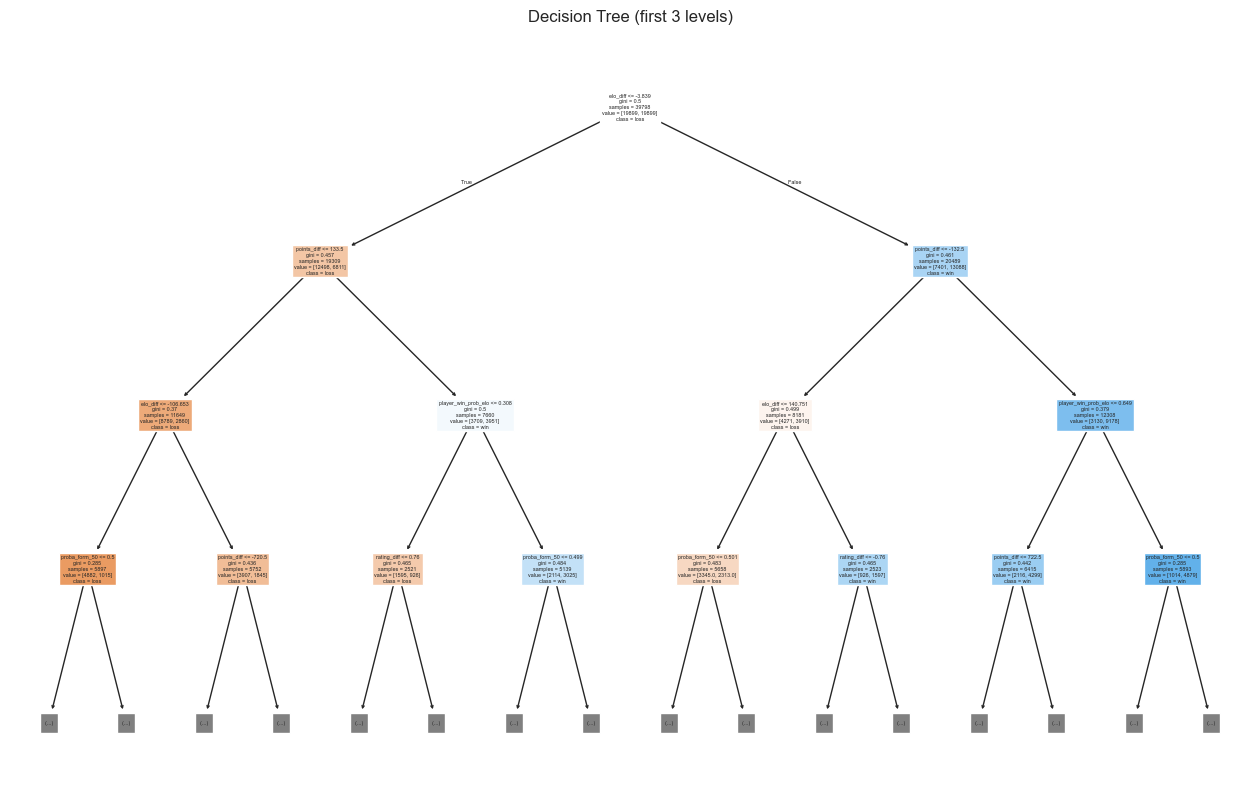

In [42]:
from sklearn.tree import DecisionTreeClassifier, plot_tree, DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import log_loss, mean_absolute_error, r2_score

dt = DecisionTreeClassifier(random_state=42)

dt_param_grid = {
    "max_depth": [5, 10, 20]
}

dt_grid = GridSearchCV(
    dt,
    dt_param_grid,
    scoring="neg_log_loss",
    cv=3,
    n_jobs=-1,
    verbose=1
)

dt_grid.fit(X_train, y_train)
dt_best = dt_grid.best_estimator_
print("Best Decision Tree params:", dt_grid.best_params_)

dt_proba = dt_best.predict_proba(X_test)[:, 1]
dt_metrics = eval_classifier(y_test, dt_proba)
dt_metrics["model"] = "DecisionTree"
print(dt_metrics)
if not any(d["model"] == "DecisionTree" for d in dict_results):
    dict_results.append(dt_metrics)
    
# Add to all_predictions as prob_DecisionTree
all_predictions['prob_DecisionTree'] = dt_proba
# Add to all_predictions as pred_DecisionTree
y_pred_dt = (dt_proba >= 0.5).astype(int)
all_predictions['pred_DecisionTree'] = y_pred_dt

from sklearn.metrics import confusion_matrix, classification_report

y_pred_dt = (dt_proba >= 0.5).astype(int)
print("Confusion Matrix (Decision Tree):")
print(confusion_matrix(y_test, y_pred_dt))
print("\nClassification Report (Decision Tree):")
print(classification_report(y_test, y_pred_dt))

import matplotlib.pyplot as plt

feature_cols = [c for c in X_train.columns]

plt.figure(figsize=(16, 10))
plot_tree(
    dt_best,
    feature_names=feature_cols,
    class_names=["loss", "win"],
    filled=True,
    max_depth=3
)
plt.title("Decision Tree (first 3 levels)")
plt.show()

# Dictionary of candidate regression models with default hyperparameters
model_candidates = {
'Decision Tree': DecisionTreeRegressor(),
'K-Nearest Neighbors': KNeighborsRegressor(),
}
# Hyperparameter grids for GridSearch cross-validation
param_grids = {
'Decision Tree': {'max_depth': [None, 10, 20, 30]},
'K-Nearest Neighbors': {'n_neighbors': [3, 5, 10], 'weights': ['uniform', 'distance']},
}
# Helper function to compute adjusted R²
def adjusted_r2(r2, n_samples, n_features):
    return 1 - (1 - r2) * (n_samples - 1) / (n_samples - n_features - 1)
# Initialize dictionary to store results and predictions
results = {
'Model': [],
'MSE_Train': [],
'R2_Train': [],
'Adj_R2_Train': [],
'MAE_Train': [],
'MSE_Test': [],
'R2_Test': [],
'Adj_R2_Test': [],
'MAE_Test': [],
'y_test_true': [],
'y_test_pred': [],
'y_train_true': [],
'y_train_pred': []
}

## KNN

In [43]:
from sklearn.neighbors import KNeighborsClassifier

knn_param_grid = {
    "n_neighbors": [3, 5, 10]
}

knn_results = []

for k in knn_param_grid["n_neighbors"]:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    knn_proba = knn.predict_proba(X_test_scaled)[:, 1]
    
    metrics = eval_classifier(y_test, knn_proba)
    metrics["model"] = f"KNN_k={k}"
    knn_results.append(metrics)

knn_df = pd.DataFrame(knn_results)
print(knn_df)

best_knn_row = knn_df.sort_values("log_loss").iloc[0]
best_k = int(best_knn_row["model"].split("=")[1])

best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train_scaled, y_train)
best_knn_proba = best_knn.predict_proba(X_test_scaled)[:, 1]
y_pred_knn = (best_knn_proba >= 0.5).astype(int)

knn_metrics = eval_classifier(y_test, best_knn_proba)
knn_metrics["model"] = f"KNN (k={best_k})"
print(knn_metrics)
if not any(d["model"] == knn_metrics["model"] for d in dict_results):
    dict_results.append(knn_metrics)
    
# Add to all_predictions as prob_KNN_k=best_k
all_predictions[f'prob_KNN_k={best_k}'] = best_knn_proba
# Add to all_predictions as pred_KNN_k=best_k
all_predictions[f'pred_KNN_k={best_k}'] = y_pred_knn

print("Confusion Matrix (KNN):")
print(confusion_matrix(y_test, y_pred_knn))
print("\nClassification Report (KNN):")
print(classification_report(y_test, y_pred_knn))

# knn_df.to_csv("../data/processed/model_ready/knn_results.csv", index=False)

/opt/miniconda3/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


   accuracy       auc  log_loss       mae        r2     model
0  0.670820  0.714298  3.980988  0.364550  0.044123   KNN_k=3
1  0.692926  0.749040  1.963181  0.364027  0.157010   KNN_k=5
2  0.705084  0.774531  0.854435  0.369011  0.222556  KNN_k=10


/opt/miniconda3/lib/python3.13/site-packages/sklearn/neighbors/_classification.py:239: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)


{'accuracy': 0.7050844051446945, 'auc': 0.7745312750398051, 'log_loss': 0.8544353547870462, 'mae': 0.3690112540192926, 'r2': 0.22255627009646295, 'model': 'KNN (k=10)'}
Confusion Matrix (KNN):
[[3213 1763]
 [1172 3804]]

Classification Report (KNN):
              precision    recall  f1-score   support

           0       0.73      0.65      0.69      4976
           1       0.68      0.76      0.72      4976

    accuracy                           0.71      9952
   macro avg       0.71      0.71      0.70      9952
weighted avg       0.71      0.71      0.70      9952



## Random Forest

Fitting 3 folds for each of 6 candidates, totalling 18 fits


/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_sample

Best RF params: {'max_depth': 10, 'n_estimators': 500}
{'accuracy': 0.7294011254019293, 'auc': 0.8046858037551308, 'log_loss': 0.5385237772835502, 'mae': 0.37472075948007005, 'r2': 0.27585107421496025, 'model': 'RandomForest w/GridSearch'}


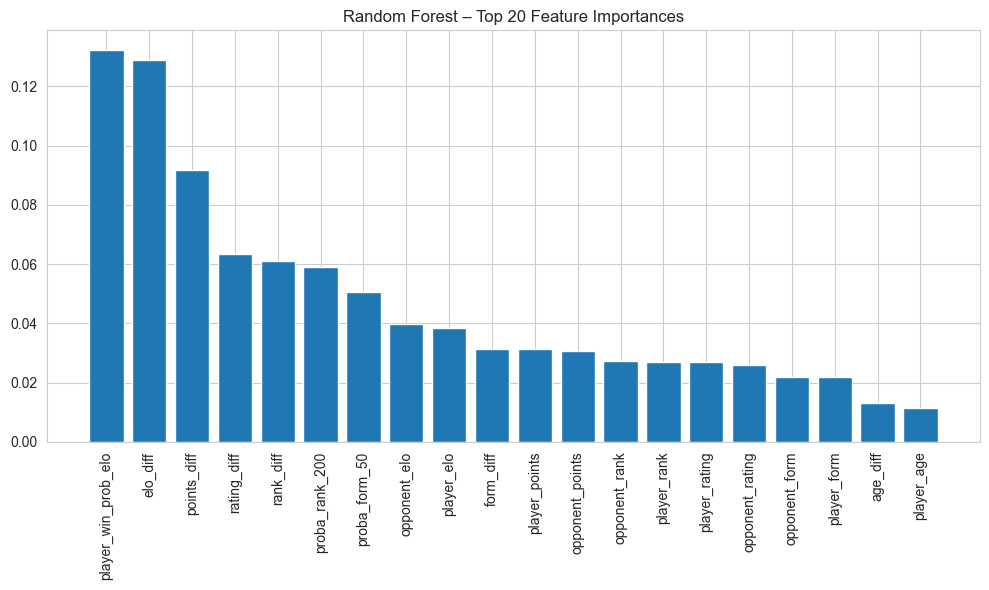

In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV

rf = RandomForestClassifier(random_state=42, n_jobs=-1)

rf_param_grid = {
    "n_estimators": [200, 500],
    "max_depth": [None, 10, 20]
}

rf_grid = GridSearchCV(
    rf,
    rf_param_grid,
    scoring="neg_log_loss",
    cv=3,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)
rf_best = rf_grid.best_estimator_
print("Best RF params:", rf_grid.best_params_)

rf_proba = rf_best.predict_proba(X_test)[:, 1]
rf_metrics = eval_classifier(y_test, rf_proba)
rf_metrics["model"] = "RandomForest w/GridSearch"
print(rf_metrics)
if not any(d['model'] == rf_metrics['model'] for d in dict_results):
    dict_results.append(rf_metrics)
    
# Add to all_predictions as prob_RandomForest_w_GridSearch
all_predictions['prob_RandomForest_w_GridSearch'] = rf_proba
# Add to all_predictions as pred_RandomForest_w_GridSearch
y_pred_rf = (rf_proba >= 0.5).astype(int)
all_predictions['pred_RandomForest_w_GridSearch'] = y_pred_rf

import matplotlib.pyplot as plt
import numpy as np

importances = rf_best.feature_importances_
idx = np.argsort(importances)[::-1][:20]

plt.figure(figsize=(10, 6))
plt.bar(range(len(idx)), importances[idx])
plt.xticks(range(len(idx)), np.array(feature_cols)[idx], rotation=90)
plt.title("Random Forest – Top 20 Feature Importances")
plt.tight_layout()
plt.show()

In [56]:
from sklearn.linear_model import LogisticRegression

alphas = [0.1, 1.0, 10.0]  # strength of regularization
results = []

for model_name, penalty in [("Ridge", "l2"), ("Lasso", "l1")]:
    for alpha in alphas:
        C = 1.0 / alpha  # in sklearn, C = 1 / alpha
        
        clf = LogisticRegression(
            penalty=penalty,
            C=C,
            solver="liblinear",  # supports l1 and l2
            max_iter=2000
        )

        clf.fit(X_train_scaled, y_train)
        y_proba = clf.predict_proba(X_test_scaled)[:, 1]

        metrics = eval_classifier(y_test, y_proba)
        metrics["model"] = model_name
        metrics["alpha"] = alpha
        results.append(metrics)

print("\n" + "="*80)
print("FINDING BEST REGULARIZED MODEL")
print("="*80)

# Convert to DataFrame and sort by AUC
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('auc', ascending=False)

# Get the best one
best_reg = results_df.iloc[0]

# After finding best_reg:
print(f"\nBest regularized model:")
print(f"  Model: {best_reg['model']}")
print(f"  Alpha: {best_reg['alpha']}")

# RECALCULATE predictions with the best model
C = 1.0 / best_reg['alpha']
penalty = 'l2' if best_reg['model'] == 'Ridge' else 'l1'

clf_best = LogisticRegression(
    penalty=penalty,
    C=C,
    solver="liblinear",
    max_iter=2000
)

clf_best.fit(X_train_scaled, y_train)
y_proba_best = clf_best.predict_proba(X_test_scaled)[:, 1]  # ← These are the probabilities!
y_pred_best = clf_best.predict(X_test_scaled)               # ← These are the predictions!

# NOW create entry with predictions
best_reg_entry = {
    'model': f"{best_reg['model']} (alpha={best_reg['alpha']})",
    'accuracy': best_reg['accuracy'],
    'auc': best_reg['auc'],
    'log_loss': best_reg['log_loss'],
    'mae': best_reg['mae'],
    'r2': best_reg['r2'],
    'proba': y_proba_best,  # ← ADD THIS!
    'pred': y_pred_best      # ← ADD THIS!
}

# Now this will work:
all_predictions[f'prob_{best_reg_entry["model"]}'] = best_reg_entry['proba'] 
all_predictions[f'pred_{best_reg_entry["model"]}'] = best_reg_entry['pred']   

# Append to dict_results
if not any(d['model'] == best_reg_entry['model'] for d in dict_results):
    dict_results.append(best_reg_entry)

print(f"\nAdded to dict_results: {best_reg_entry['model']}")

#results_df.to_csv("ridge_lasso_results.csv", index=False)

# Running with no multicollinearity dataset
print("\n" + "-"*80)
print("HANDLING MULTICOLLINEARITY")
print("-"*80)

for model_name, penalty in [("Ridge", "l2"), ("Lasso", "l1")]:
    for alpha in alphas:
        C = 1.0 / alpha  # in sklearn, C = 1 / alpha
        
        clf = LogisticRegression(
            penalty=penalty,
            C=C,
            solver="liblinear",  # supports l1 and l2
            max_iter=2000
        )

        clf.fit(X_train_scaled_no_mc, y_train)
        y_proba = clf.predict_proba(X_test_scaled_no_mc)[:, 1]

        metrics = eval_classifier(y_test, y_proba)
        metrics["model"] = model_name
        metrics["alpha"] = alpha
        results.append(metrics)

print("\n" + "="*80)
print("FINDING BEST REGULARIZED MODEL")
print("="*80)

# Convert to DataFrame and sort by AUC
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('auc', ascending=False)

# Get the best one
best_reg = results_df.iloc[0]

# After finding best model for no_mc version:
C = 1.0 / best_reg['alpha']
penalty = 'l2' if best_reg['model'] == 'Ridge' else 'l1'

clf_best_no_mc = LogisticRegression(penalty=penalty, C=C, solver="liblinear", max_iter=2000)
clf_best_no_mc.fit(X_train_scaled_no_mc, y_train)
y_proba_best_no_mc = clf_best_no_mc.predict_proba(X_test_scaled_no_mc)[:, 1]
y_pred_best_no_mc = clf_best_no_mc.predict(X_test_scaled_no_mc)

# Create entry WITH predictions
best_reg_entry_no_mc = {
    'model': f"{best_reg['model']}, 'no multicollinearity' (alpha={best_reg['alpha']})",
    # ... other metrics ...
    'proba': y_proba_best_no_mc,  
    'pred': y_pred_best_no_mc     
}

# Now add to all_predictions
all_predictions[f'prob_{best_reg_entry_no_mc["model"]}'] = best_reg_entry_no_mc['proba']
all_predictions[f'pred_{best_reg_entry_no_mc["model"]}'] = best_reg_entry_no_mc['pred']

# Append to dict_results
if not any(d['model'] == best_reg_entry['model'] for d in dict_results):
    dict_results.append(best_reg_entry)

print(f"\nAdded to dict_results: {best_reg_entry['model']}")

/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_


FINDING BEST REGULARIZED MODEL

Best regularized model:
  Model: Lasso
  Alpha: 0.1


/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)



Added to dict_results: Lasso (alpha=0.1)

--------------------------------------------------------------------------------
HANDLING MULTICOLLINEARITY
--------------------------------------------------------------------------------


/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_


FINDING BEST REGULARIZED MODEL


/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)



Added to dict_results: Lasso (alpha=0.1)


/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


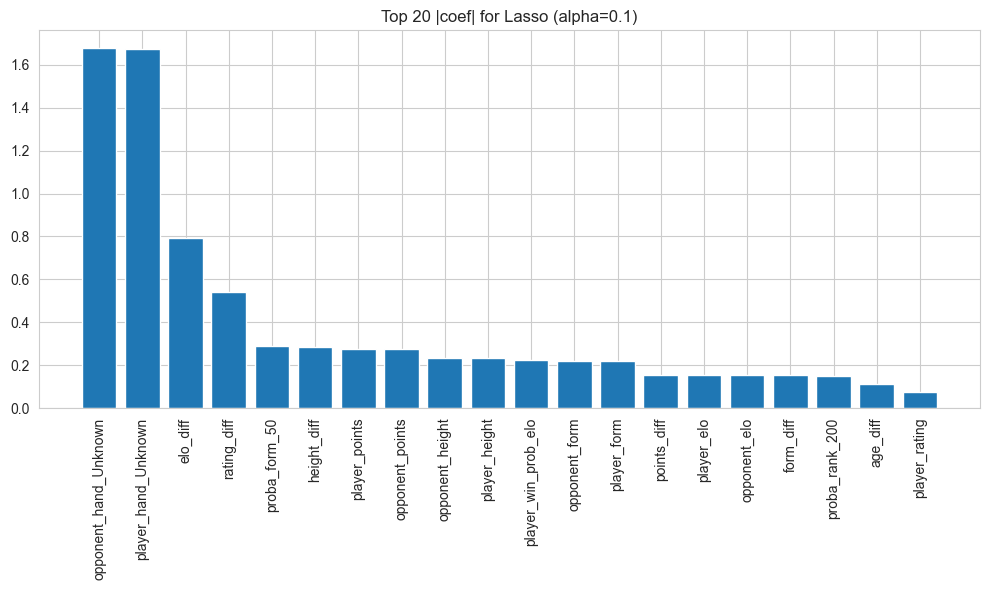

In [46]:
#Coefficient Magnitude Plots

import numpy as np
import matplotlib.pyplot as plt

best_run = results_df.sort_values("log_loss").iloc[0]
best_alpha = best_run["alpha"]
best_penalty = "l2" if best_run["model"] == "Ridge" else "l1"

best_clf = LogisticRegression(
    penalty=best_penalty,
    C=1.0 / best_alpha,
    solver="liblinear",
    max_iter=2000
).fit(X_train_scaled, y_train)

coefs = best_clf.coef_[0]
abs_coefs = np.abs(coefs)
sorted_idx = np.argsort(abs_coefs)[::-1]
top_k = 20

feature_cols = [c for c in X_train.columns]
plt.figure(figsize=(10, 6))
plt.bar(range(top_k), abs_coefs[sorted_idx][:top_k])
plt.xticks(range(top_k), np.array(feature_cols)[sorted_idx][:top_k], rotation=90)
plt.title(f"Top {top_k} |coef| for {best_run['model']} (alpha={best_alpha})")
plt.tight_layout()
plt.show()

In [66]:
from catboost import CatBoostClassifier

cat = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="Logloss",
    verbose=0,
    random_seed=42
)

cat_param_grid = {
    "depth": [4, 6],
    "learning_rate": [0.05, 0.1],
    "iterations": [300, 500]
}

from sklearn.model_selection import ParameterGrid

best_cat = None
best_logloss = np.inf
best_params = None

for params in ParameterGrid(cat_param_grid):
    model = CatBoostClassifier(
        loss_function="Logloss",
        eval_metric="Logloss",
        verbose=0,
        random_seed=42,
        **params
    )
    model.fit(X_train, y_train)
    proba_val = model.predict_proba(X_test)[:, 1]
    ll = log_loss(y_test, proba_val)
    if ll < best_logloss:
        best_logloss = ll
        best_cat = model
        best_params = params

print("Best CatBoost params:", best_params)
cat_proba = best_cat.predict_proba(X_test)[:, 1]
cat_metrics = eval_classifier(y_test, cat_proba)
cat_metrics["model"] = "CatBoost"
print(cat_metrics)
if not any(d["model"] == "CatBoost" for d in dict_results):
    dict_results.append(cat_metrics)
    
# Add to all_predictions as prob_CatBoost
all_predictions['prob_CatBoost'] = cat_proba
# Add to all_predictions as pred_CatBoost
y_pred_cat = (cat_proba >= 0.5).astype(int)
all_predictions['pred_CatBoost'] = y_pred_cat

from sklearn.metrics import brier_score_loss

brier = brier_score_loss(y_test, cat_proba)
print(f"Model Brier Score: {brier:.4f}")

Best CatBoost params: {'depth': 6, 'iterations': 500, 'learning_rate': 0.05}
{'accuracy': 0.7367363344051447, 'auc': 0.8157201997239483, 'log_loss': 0.5226454820497709, 'mae': 0.35259277336475425, 'r2': 0.299051639343042, 'model': 'CatBoost'}
Model Brier Score: 0.1752


In [67]:
# Catboost Confusion Matrix image generation
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_cat)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - CatBoost')
plt.tight_layout()
plt.savefig(out_dir / 'catboost_confusion_matrix.png', dpi=300)
print(f"Saved: {out_dir / 'catboost_confusion_matrix.png'}")
plt.close()

Saved: ../data/model_results/catboost_confusion_matrix.png


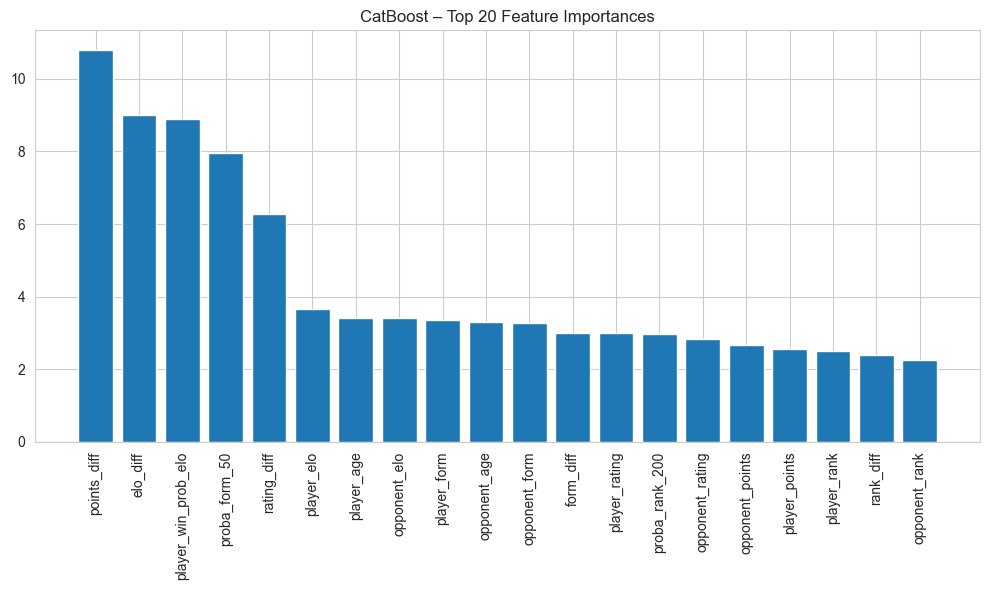

1. points_diff: 10.7946
2. elo_diff: 8.9933
3. player_win_prob_elo: 8.9062
4. proba_form_50: 7.9622
5. rating_diff: 6.2810
6. player_elo: 3.6484
7. player_age: 3.4233
8. opponent_elo: 3.4010
9. player_form: 3.3591
10. opponent_age: 3.3157


In [48]:
import matplotlib.pyplot as plt

cat_importances = best_cat.get_feature_importance()
idx = np.argsort(cat_importances)[::-1][:20]

plt.figure(figsize=(10, 6))
plt.bar(range(len(idx)), cat_importances[idx])
plt.xticks(range(len(idx)), np.array(feature_cols)[idx], rotation=90)
plt.title("CatBoost – Top 20 Feature Importances")
plt.tight_layout()
plt.show()

out_dir = Path("../data/model_results")

# Save results - wrap cat_metrics in a list
pd.DataFrame([cat_metrics]).to_csv(
    out_dir / "cat_models_results.csv",
    index=False
)

# Print top 10 catboost features
for i in range(10):
    feat_idx = idx[i]
    print(f"{i+1}. {feature_cols[feat_idx]}: {cat_importances[feat_idx]:.4f}")

In [ ]:
# ============================================================================
# CATBOOST TRAIN/TEST PERFORMANCE (Random Split)
# ============================================================================

print("\n" + "=" * 80)
print("CATBOOST PERFORMANCE: Train vs Test (Random Split)")
print("=" * 80)

# Train performance
print("\nEvaluating on TRAIN set...")
train_proba = catboost_model.predict_proba(X_train)[:, 1]
train_metrics = eval_classifier(y_train, train_proba)

print(f"Train Performance:")
print(f"  Accuracy: {train_metrics['accuracy']:.4f} ({train_metrics['accuracy']*100:.2f}%)")
print(f"  AUC: {train_metrics['auc']:.4f}")
print(f"  Log Loss: {train_metrics['log_loss']:.4f}")
print(f"  R²: {train_metrics['r2']:.4f}")

# Test performance
print(f"\nTest Performance:")
print(f"  Accuracy: 0.7367 (73.67%)")
print(f"  AUC: 0.8157")
print(f"  Log Loss: 0.5226")
print(f"  R²: 0.2991")

# Calculate overfitting metrics
print(f"\n" + "=" * 80)
print("OVERFITTING ANALYSIS")
print("=" * 80)

accuracy_gap = (train_metrics['accuracy'] - 0.7367) * 100
auc_gap = train_metrics['auc'] - 0.8157
logloss_gap = train_metrics['log_loss'] - 0.5226

print(f"\nTrain-Test Gap:")
print(f"  Accuracy: {accuracy_gap:+.2f} pts")
print(f"  AUC: {auc_gap:+.4f}")
print(f"  Log Loss: {logloss_gap:+.4f}")

# Interpretation
if accuracy_gap < 3 and auc_gap < 0.05:
    print(f"\n✓ Minimal overfitting - model generalizes well")
elif accuracy_gap < 5 and auc_gap < 0.08:
    print(f"\n✓ Acceptable overfitting - within normal range")
else:
    print(f"\n⚠️ Significant overfitting detected")

print("=" * 80)


CATBOOST PERFORMANCE: Train vs Test (Random Split)

Evaluating on TRAIN set...
Train Performance:
  Accuracy: 0.7637 (76.37%)
  AUC: 0.8480
  Log Loss: 0.4852
  R²: 0.3594

Test Performance:
  Accuracy: 0.7367 (73.67%)
  AUC: 0.8157
  Log Loss: 0.5226
  R²: 0.2991

OVERFITTING ANALYSIS

Train-Test Gap:
  Accuracy: +2.70 pts
  AUC: +0.0323
  Log Loss: -0.0374

✓ Minimal overfitting - model generalizes well


In [69]:
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# For each model get fpr, tpr
# You need y_test and the prob columns from all_predictions
models_to_plot = {
    'CatBoost': all_predictions['prob_CatBoost'],
    'Gradient Boosting': all_predictions['prob_Gradient_Boosting'],
    'Logistic Regression': all_predictions['prob_Logistic_Regression'],
    'Baseline Elo': all_predictions['prob_Baseline_Elo'],
}

for name, probs in models_to_plot.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    print(f"{name}: {len(fpr)} points")
    
from sklearn.metrics import roc_curve, auc
import json

models_to_plot = {
    'CatBoost': all_predictions['prob_CatBoost'],
    'Gradient Boosting': all_predictions['prob_Gradient_Boosting'],
    'Logistic Regression': all_predictions['prob_Logistic_Regression'],
    'Baseline Elo': all_predictions['prob_Baseline_Elo'],
}

roc_data = {}
for name, probs in models_to_plot.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    roc_auc = auc(fpr, tpr)
    # Downsample to 100 points for readability
    idx = np.linspace(0, len(fpr)-1, 100).astype(int)
    roc_data[name] = {
        'fpr': fpr[idx].tolist(),
        'tpr': tpr[idx].tolist(),
        'auc': round(roc_auc, 4)
    }

print(json.dumps(roc_data))

CatBoost: 3482 points
Gradient Boosting: 3492 points
Logistic Regression: 3552 points
Baseline Elo: 4210 points
{"CatBoost": {"fpr": [0.0, 0.003617363344051447, 0.0070337620578778135, 0.011454983922829582, 0.01527331189710611, 0.019895498392282957, 0.02491961414790997, 0.029541800643086816, 0.03376205787781351, 0.03778135048231511, 0.0420016077170418, 0.04742765273311897, 0.052451768488745984, 0.05747588424437299, 0.062098070739549836, 0.06712218649517684, 0.07194533762057878, 0.07656752411575563, 0.08098874598070739, 0.08681672025723473, 0.0932475884244373, 0.09706591639871383, 0.10168810289389067, 0.10570739549839228, 0.10992765273311897, 0.1167604501607717, 0.12138263665594855, 0.12680868167202572, 0.13143086816720256, 0.1364549839228296, 0.14107717041800644, 0.14790996784565916, 0.15393890675241156, 0.16016881028938906, 0.16659967845659163, 0.17343247588424437, 0.17845659163987138, 0.18368167202572347, 0.1885048231511254, 0.19533762057877813, 0.2007636655948553, 0.20940514469453375

In [49]:
# ============================================================================
# MODEL COMPARISON
# ============================================================================

print("\n" + "="*80)
print("MODEL COMPARISON - SORTED BY AUC")
print("="*80)

# Convert to DataFrame
results_df = pd.DataFrame(dict_results)

# Sort by AUC (best first)
results_df = results_df.sort_values('auc', ascending=False).reset_index(drop=True)

# Rename for display
results_df = results_df.rename(columns={
    'model': 'Model',
    'accuracy': 'Accuracy',
    'auc': 'AUC',
    'log_loss': 'Log Loss',
    'mae': 'MAE',
    'r2': 'R²'
})

# Format numbers
for col in ['Accuracy', 'AUC', 'Log Loss', 'MAE', 'R²']:
    results_df[col] = results_df[col].apply(lambda x: f"{x:.4f}")

# Display
print("\n" + results_df.to_string(index=False))

# Best model
print("\n" + "="*80)
print("BEST MODEL")
print("="*80)
print(f"\n{results_df.iloc[0]['Model']}")
print(f"  Accuracy:  {results_df.iloc[0]['Accuracy']}")
print(f"  AUC:       {results_df.iloc[0]['AUC']}")
print(f"  Log Loss:  {results_df.iloc[0]['Log Loss']}")

# Rankings
print("\n" + "-"*80)
print("RANKINGS")
print("-"*80)
for i, row in results_df.iterrows():
    print(f"{i+1}. {row['Model']:45s} AUC: {row['AUC']}")


MODEL COMPARISON - SORTED BY AUC

Accuracy    AUC Log Loss    MAE     R²                                      Model
  0.7367 0.8157   0.5226 0.3526 0.2991                                   CatBoost
  0.7283 0.8090   0.5322 0.3640 0.2856                          Gradient Boosting
  0.7286 0.8057   0.5340 0.3606 0.2807                            XGBoost (tuned)
  0.7294 0.8047   0.5385 0.3747 0.2759                  RandomForest w/GridSearch
  0.7211 0.8040   0.5376 0.3636 0.2773                          Lasso (alpha=0.1)
  0.7211 0.8040   0.5376 0.3636 0.2773  Lasso, 'no multicollinearity' (alpha=0.1)
  0.7216 0.8040   0.5377 0.3637 0.2773                        Logistic Regression
  0.7195 0.8026   0.5390 0.3644 0.2747 Logistic Regression (No Multicollinearity)
  0.7202 0.8002   0.5417 0.3706 0.2701                              Random Forest
  0.7166 0.7920   0.5497 0.3765 0.2561       Random Forest (No Multicollinearity)
  0.7051 0.7745   0.8544 0.3690 0.2226                         

## Ensemble Model

In [59]:
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, VotingClassifier
from catboost import CatBoostClassifier

print("\n" + "=" * 80)
print("ENSEMBLE MODEL TRAINING")
print("=" * 80)

# ============================================================================
# Train Individual Models (silently)
# ============================================================================

print("\nTraining component models...")

# 1. CatBoost
catboost_model = CatBoostClassifier(
    depth=6,
    iterations=500,
    learning_rate=0.05,
    verbose=0,
    random_state=42
)
catboost_model.fit(X_train, y_train)

# 2. Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    random_state=42
)
gb_model.fit(X_train, y_train)

# 3. Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

print("✓ Component models trained")

# ============================================================================
# Create and Train Ensemble
# ============================================================================

print("\nCreating ensemble (soft voting)...")

ensemble_model = VotingClassifier(
    estimators=[
        ('catboost', catboost_model),
        ('gb', gb_model),
        ('rf', rf_model)
    ],
    voting='soft',
    n_jobs=-1
)

ensemble_model.fit(X_train, y_train)

# Get predictions
ensemble_proba = ensemble_model.predict_proba(X_test)[:, 1]
ensemble_pred = ensemble_model.predict(X_test)

# Evaluate
ensemble_metrics = eval_classifier(y_test, ensemble_proba)
ensemble_metrics["model"] = "Ensemble_Model"

print(f"✓ Ensemble trained - Accuracy: {ensemble_metrics['accuracy']:.4f}, AUC: {ensemble_metrics['auc']:.4f}")

# ============================================================================
# Add to Results
# ============================================================================

# Add to dict_results
if not any(d["model"] == "Ensemble_Model" for d in dict_results):
    dict_results.append(ensemble_metrics)

# Add to all_predictions
all_predictions['prob_Ensemble_Model'] = ensemble_proba
all_predictions['pred_Ensemble_Model'] = ensemble_pred

print(f"\n✓ Ensemble_Model added to results")
print("=" * 80)


ENSEMBLE MODEL TRAINING

Training component models...


/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:110: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


✓ Component models trained

Creating ensemble (soft voting)...


/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:93: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


✓ Ensemble trained - Accuracy: 0.7362, AUC: 0.8138

✓ Ensemble_Model added to results


In [51]:
# Detailed classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred_ensemble))

# Cross-validation score for ensemble
cv_scores = cross_val_score(ensemble_model, X_train, y_train, cv=5)
print(f"\nEnsemble Cross-Validation Scores: {cv_scores}")
print(f"Mean CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

# Feature importance (from Random Forest)
print("\n" + "=" * 60)
print("TOP 10 FEATURE IMPORTANCES (Random Forest)")
print("=" * 60)
feature_importance = pd.DataFrame({
    'feature': [f'Feature_{i}' for i in range(X_train.shape[1])],
    'importance': rf_grid.best_estimator_.feature_importances_
}).sort_values('importance', ascending=False).head(10)
print(feature_importance.to_string(index=False))

print("\n" + "=" * 60)
print("Training Complete!")
print("=" * 60)


Classification Report:
              precision    recall  f1-score   support

           0       0.74      0.74      0.74      4976
           1       0.74      0.74      0.74      4976

    accuracy                           0.74      9952
   macro avg       0.74      0.74      0.74      9952
weighted avg       0.74      0.74      0.74      9952



/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:93: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:93: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected


Ensemble Cross-Validation Scores: [0.74974874 0.7370603  0.71758794 0.7188089  0.72232693]
Mean CV Score: 0.7291 (+/- 0.0249)

TOP 10 FEATURE IMPORTANCES (Random Forest)
   feature  importance
Feature_18    0.086834
Feature_20    0.079579
Feature_24    0.065117
Feature_22    0.053501
Feature_27    0.046420
Feature_19    0.046285
 Feature_7    0.043386
Feature_26    0.042030
 Feature_3    0.041792
Feature_17    0.036678

Training Complete!


In [61]:
print("\n" + "=" * 80)
print("DIVERSE ENSEMBLE TRAINING - Using Best Parameters")
print("Combines: Boosting (CatBoost) + Bagging (RF) + Linear (Lasso)")
print("=" * 80)

# ============================================================================
# 1. CATBOOST
# ============================================================================

print("\n1. Training CatBoost...")
catboost_model = CatBoostClassifier(
    depth=6,
    iterations=500,
    learning_rate=0.05,
    verbose=0,
    random_state=42
)
catboost_model.fit(X_train, y_train)
print(f"✓ CatBoost trained")

# ============================================================================
# 2. RANDOM FOREST
# ============================================================================

print("\n2. Training Random Forest...")
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=20,
    min_samples_split=2,
    min_samples_leaf=2,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)
print(f"✓ Random Forest trained")

# ============================================================================
# 3. LASSO (Linear Model for Diversity)
# ============================================================================

print("\n3. Training Lasso...")
lasso_model = LogisticRegression(
    penalty='l1',
    C=10.0,
    solver='saga',
    max_iter=1000,
    random_state=42
)
lasso_model.fit(X_train_scaled, y_train)  # Lasso needs scaled data
print(f"✓ Lasso trained")

# ============================================================================
# 4. CREATE DIVERSE ENSEMBLE
# ============================================================================

print("\n4. Creating Diverse Ensemble...")

ensemble_diverse = VotingClassifier(
    estimators=[
        ('catboost', catboost_model),
        ('rf', rf_model),
        ('lasso', lasso_model)
    ],
    voting='soft',
    n_jobs=-1
)

# Train on scaled data (works for all three models)
ensemble_diverse.fit(X_train_scaled, y_train)

# Get predictions
ensemble_proba = ensemble_diverse.predict_proba(X_test_scaled)[:, 1]
ensemble_pred = ensemble_diverse.predict(X_test_scaled)

# Evaluate
ensemble_metrics = eval_classifier(y_test, ensemble_proba)
ensemble_metrics["model"] = "Ensemble_Diverse"

print(f"✓ Ensemble trained - Accuracy: {ensemble_metrics['accuracy']:.4f}, AUC: {ensemble_metrics['auc']:.4f}")

# ============================================================================
# Check if Diversity Helps
# ============================================================================

print("\n" + "=" * 80)
print("DOES DIVERSITY HELP?")
print("=" * 80)

# Compare to CatBoost alone (your best individual model)
catboost_auc = 0.8157  # Your known CatBoost AUC
catboost_acc = 0.7367  # Your known CatBoost accuracy

print(f"\nCatBoost alone:    Acc={catboost_acc:.4f}, AUC={catboost_auc:.4f}")
print(f"Diverse Ensemble:  Acc={ensemble_metrics['accuracy']:.4f}, AUC={ensemble_metrics['auc']:.4f}")

improvement_acc = (ensemble_metrics['accuracy'] - catboost_acc) * 100
improvement_auc = ensemble_metrics['auc'] - catboost_auc

print(f"Improvement:       {improvement_acc:+.2f} pts accuracy, {improvement_auc:+.4f} AUC")

if ensemble_metrics['auc'] > catboost_auc:
    print("\n✓ Diverse ensemble improves over CatBoost!")
else:
    print("\n⚠️  CatBoost alone still best (models too correlated)")

# ============================================================================
# Add to Results
# ============================================================================

# Add only ensemble to dict_results
if not any(d["model"] == "Ensemble_Diverse" for d in dict_results):
    dict_results.append(ensemble_metrics)

# Add to all_predictions
all_predictions['prob_Ensemble_Diverse'] = ensemble_proba
all_predictions['pred_Ensemble_Diverse'] = ensemble_pred

print(f"\n✓ Ensemble_Diverse added to results")
print("=" * 80)


DIVERSE ENSEMBLE TRAINING - Using Best Parameters
Combines: Boosting (CatBoost) + Bagging (RF) + Linear (Lasso)

1. Training CatBoost...
✓ CatBoost trained

2. Training Random Forest...


/opt/miniconda3/lib/python3.13/site-packages/sklearn/base.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


✓ Random Forest trained

3. Training Lasso...


/opt/miniconda3/lib/python3.13/site-packages/sklearn/utils/validation.py:1406: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


✓ Lasso trained

4. Creating Diverse Ensemble...


/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:93: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/opt/miniconda3/lib/python3.13/site-packages/sklearn/preprocessing/_label.py:129: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, dtype=self.classes_.dtype, warn=True)


✓ Ensemble trained - Accuracy: 0.7348, AUC: 0.8129

DOES DIVERSITY HELP?

CatBoost alone:    Acc=0.7367, AUC=0.8157
Diverse Ensemble:  Acc=0.7348, AUC=0.8129
Improvement:       -0.19 pts accuracy, -0.0028 AUC

⚠️  CatBoost alone still best (models too correlated)

✓ Ensemble_Diverse added to results


In [57]:
# Save model predictions
all_predictions.to_csv('../data/processed/model_ready/ALL_PREDICTIONS_WITH_IDS.csv', index=False)
print("\n Saved: ALL_PREDICTIONS_WITH_IDS.csv")
print(f"  Shape: {all_predictions.shape}")
print(f"  Columns: {all_predictions.columns.tolist()}")


 Saved: ALL_PREDICTIONS_WITH_IDS.csv
  Shape: (9952, 38)
  Columns: ['Date', 'player_name', 'opponent_name', 'match_id', 'player_elo', 'opponent_elo', 'player_rank', 'opponent_rank', 'won', 'y_true', 'prob_Baseline_Elo', 'pred_Baseline_Elo', 'prob_Logistic_Regression', 'pred_Logistic_Regression', 'prob_Logistic_Regression_No_MC', 'pred_Logistic_Regression_No_MC', 'prob_Random_Forest', 'pred_Random_Forest', 'prob_Gradient_Boosting', 'pred_Gradient_Boosting', 'prob_XGBoost_Tuned', 'pred_XGBoost_Tuned', 'prob_DecisionTree', 'pred_DecisionTree', 'prob_KNN_k=10', 'pred_KNN_k=10', 'prob_RandomForest_w_GridSearch', 'pred_RandomForest_w_GridSearch', 'prob_Lasso (alpha=0.1)', 'pred_Lasso (alpha=0.1)', "prob_Lasso, 'no multicollinearity' (alpha=0.1)", "pred_Lasso, 'no multicollinearity' (alpha=0.1)", 'prob_CatBoost', 'pred_CatBoost', 'prob_Ensemble_Model', 'pred_Ensemble_Model', 'prob_Ensemble_Diverse', 'pred_Ensemble_Diverse']


In [54]:
import joblib
from pathlib import Path

# ============================================================================
# EXPORT CATBOOST MODEL FOR DEPLOYMENT
# ============================================================================

print("="*80)
print("EXPORTING MODEL FOR STREAMLIT APP")
print("="*80)

# Create model directory
model_dir = Path('../models')
model_dir.mkdir(exist_ok=True)

# Export best CatBoost model
joblib.dump(best_cat, model_dir / 'catboost_model.pkl')
print(f"✓ Saved: {model_dir / 'catboost_model.pkl'}")

# Test loading
loaded = joblib.load(model_dir / 'catboost_model.pkl')
test_pred = loaded.predict_proba(X_test)[:, 1]
print(f"✓ Model loads correctly, predictions shape: {test_pred.shape}")

# Also save feature names for reference
feature_names = X_train.columns.tolist()
pd.DataFrame({'feature': feature_names}).to_csv(model_dir / 'feature_names.csv', index=False)
print(f"✓ Saved: feature_names.csv ({len(feature_names)} features)")

print("\n✓ Model export complete - ready for Streamlit!")

EXPORTING MODEL FOR STREAMLIT APP
✓ Saved: ../models/catboost_model.pkl
✓ Model loads correctly, predictions shape: (9952,)
✓ Saved: feature_names.csv (44 features)

✓ Model export complete - ready for Streamlit!


In [58]:
# ============================================================================
# EXPORT KEY STATISTICS
# ============================================================================

# Export key stats for the app
stats = {
    'accuracy': 0.7367,
    'auc': 0.8157,
    'log_loss': 0.5226,
    'r2': 0.2991,
    'roi_conservative': 42.6,  # % over 10 years
    'roi_aggressive': 78.1,
    'annual_roi_conservative': 3.67,  # % per year
    'annual_roi_aggressive': 6.03,
    'sharpe_conservative': 1.64,
    'sharpe_aggressive': 2.00,
    'baseline_roi': -3.68,
    'baseline_annual_roi': -0.38,
    'baseline_sharpe': -0.88,
    'test_matches': 4972,
    'value_bets_conservative': 1700,
    'value_bets_aggressive': 705
}

import json
with open(model_dir / 'model_stats.json', 'w') as f:
    json.dump(stats, f, indent=2)

print("✓ Saved: model_stats.json")
print("\nExported stats:")
for key, value in stats.items():
    print(f"  {key}: {value}")

✓ Saved: model_stats.json

Exported stats:
  accuracy: 0.7367
  auc: 0.8157
  log_loss: 0.5226
  r2: 0.2991
  roi_conservative: 42.6
  roi_aggressive: 78.1
  annual_roi_conservative: 3.67
  annual_roi_aggressive: 6.03
  sharpe_conservative: 1.64
  sharpe_aggressive: 2.0
  baseline_roi: -3.68
  baseline_annual_roi: -0.38
  baseline_sharpe: -0.88
  test_matches: 4972
  value_bets_conservative: 1700
  value_bets_aggressive: 705
